## Setup

These constants are used by every later cell. Training uses the full stratified split. Set either cap to an integer if a later run needs a smaller sample.


In [ ]:
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
COLORS = {"grid": "#2878B5", "solar": "#E3A018", "generator": "#C4473A", "unknown": "#777777"}
CLASSES = ["grid", "solar", "generator"]

# None means every row in that split.
MAX_TRAIN_ROWS = 1_000_000
MAX_TEST_ROWS = 300_000

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


## Read the sensor file

Unzip with Python and load the Sierra Leone CSV with pandas. Pandas has no worksheet row limit, so this keeps the rows Excel would drop. The cell reports the row count and warns if the file is still at that Excel cutoff.


In [ ]:
zip_path = Path(ZIP_PATH)
if not zip_path.exists():
    raise FileNotFoundError(f"Cannot find {zip_path}. Mount Drive in the previous cell and leave ZIP_PATH unchanged.")
print(f"Reading archive: {zip_path}")

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
existing = [item for item in EXTRACT_DIR.rglob("labeled_power_source_data.csv") if "__MACOSX" not in item.parts]
if not existing:
    with zipfile.ZipFile(zip_path) as archive:
        csv_names = [name for name in archive.namelist() if name.endswith("labeled_power_source_data.csv") and not name.startswith("__MACOSX")]
        print(f"Zip entries: {len(archive.namelist()):,}. Sierra Leone CSV entries: {len(csv_names)}")
        if not csv_names:
            raise FileNotFoundError("The zip does not contain labeled_power_source_data.csv.")
        archive.extractall(EXTRACT_DIR)
    existing = [item for item in EXTRACT_DIR.rglob("labeled_power_source_data.csv") if "__MACOSX" not in item.parts]
if len(existing) != 1:
    raise FileNotFoundError(f"Expected one labeled_power_source_data.csv, found: {existing}")

DATA_PATH = existing[0]
print(f"Reading {DATA_PATH} ({DATA_PATH.stat().st_size / 1e6:.1f} MB) with pandas.")
raw = pd.read_csv(DATA_PATH, dtype={"respondent_id": "string"}, low_memory=False)
N_RAW = len(raw)
print(f"Original file: {N_RAW:,} rows and {raw.shape[1]} columns")
print("Column names:", raw.columns.tolist())

EXCEL_DATA_ROWS = 1_048_575
if N_RAW <= EXCEL_DATA_ROWS:
    print(
        "This file has at most Excel's data-row limit (1,048,575). "
        "Pandas cannot recover rows that are no longer in the file."
    )
else:
    print("Row count is above Excel's worksheet limit, so the extra rows were read.")
display(raw.head())
raw.info()


Reading archive: /content/drive/MyDrive/Document from JJermaine
Zip entries: 13. Sierra Leone CSV entries: 1
Reading /content/kamilimu_data/Kamilimu_Case_Study_Dataset/Sierra Leone/labeled_power_source_data.csv (789.0 MB) with pandas.
Original file: 5,125,181 rows and 9 columns
Column names: ['Unnamed: 0', 'respondent_id', 'time', 'site_id', 'room', 'voltage', 'frequency', 'available_power_sources', 'active_power_source']
Row count is above Excel's worksheet limit, so the extra rows were read.


,Unnamed: 0,respondent_id,time,site_id,room,voltage,frequency,available_power_sources,active_power_source
0,0,37B7AE20,2023-04-25 21:46:10,princess_christian,Operating Theatre - Grid w/Solar & Generator B...,244.695898,50.327126,Grid w/Solar & Generator Backup,grid
1,1,3393AD1E,2023-04-25 21:46:03,princess_christian,High Denpendency Unit - Solar w/Grid Backup,243.988685,50.281577,Solar w/Grid Backup,grid
2,2,358F181D,2023-04-25 21:46:03,princess_christian,HOD (Office) - Solar w/Grid Backup,244.695898,50.279049,Solar w/Grid Backup,grid
3,3,E3670099,2023-04-25 21:46:03,princess_christian,Ward 2 - Grid w/Solar Backup,243.988685,50.281577,Grid w/Solar Backup,grid
4,4,41570E47,2023-04-25 21:46:03,princess_christian,Ward 2 - Grid w/Solar Backup,243.281471,50.301811,Grid w/Solar Backup,grid


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5125181 entries, 0 to 5125180
Data columns (total 9 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   Unnamed: 0               int64  
 1   respondent_id            string 
 2   time                     object 
 3   site_id                  object 
 4   room                     object 
 5   voltage                  float64
 6   frequency                float64
 7   available_power_sources  object 
 8   active_power_source      object 
dtypes: float64(2), int64(1), object(5), string(1)
memory usage: 351.9+ MB


## Check required columns

Modelling needs a timestamp, both electrical measurements, the site, the installed configuration, and the rule label. This cell counts missing values and stops if one of those columns is absent.


In [ ]:
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing values"))
required_columns = {"time", "voltage", "frequency", "site_id", "available_power_sources", "active_power_source"}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f"The CSV is missing required columns: {sorted(missing_columns)}")
print("All required analysis columns are present.")


,missing values
Unnamed: 0,0
respondent_id,0
time,0
site_id,0
room,0
voltage,0
frequency,0
available_power_sources,0
active_power_source,0


All required analysis columns are present.


## Label counts in the original file

This counts every row by the rule label before any cleaning. The share is that count divided by the number of rows in the file.


In [ ]:
labels = raw["active_power_source"].astype("string").str.strip().str.lower()
labels = labels.mask(labels.isna() | labels.eq(""), "(missing)")
label_order = ["grid", "solar", "generator", "unknown"]
label_summary = labels.value_counts().rename("rows").to_frame()
label_summary["share"] = label_summary["rows"] / len(raw)
ordered = [name for name in label_order if name in label_summary.index]
ordered += [name for name in label_summary.index if name not in ordered]
display(label_summary.loc[ordered].style.format({"rows": "{:,.0f}", "share": "{:.1%}"}))
print(f"Rows in the file: {len(raw):,}")

,rows,share
active_power_source,,
grid,"2,403,874",46.9%
solar,"2,160,602",42.2%
generator,"547,765",10.7%
unknown,"12,940",0.3%


Rows in the file: 5,125,181


## Start the cleaning record

Rows removed later are stored in a quarantine table with a reason. The labelled table plus the quarantine table must add back to the original row count.


In [ ]:
clean = raw.copy().reset_index(drop=True)
drop_log = []
quarantine_parts = []

def exclude_rows(frame, mask, reason, evidence):
    mask = pd.Series(mask, index=frame.index).fillna(False).astype(bool)
    removed = frame.loc[mask].copy()
    if not removed.empty:
        removed["drop_reason"] = reason
        quarantine_parts.append(removed)
    drop_log.append({"step": len(drop_log) + 1, "reason": reason, "evidence_or_rule": evidence, "rows_removed": int(mask.sum())})
    print(f"{reason}: {int(mask.sum()):,} rows moved to quarantine")
    return frame.loc[~mask].copy().reset_index(drop=True)

print(f"Audit trail started for {N_RAW:,} original rows.")


Audit trail started for 5,125,181 original rows.


## Parse timestamps

Timestamps are read as day/month/year hour:minute. Rows that still cannot be parsed are quarantined, because later features depend on the order of readings from each sensor.


In [ ]:
time_text = clean["time"].astype("string").str.strip()
parsed_time = pd.to_datetime(time_text, format="%d/%m/%Y %H:%M", errors="coerce")
fallback_mask = parsed_time.isna()
if fallback_mask.any():
    parsed_time.loc[fallback_mask] = pd.to_datetime(time_text.loc[fallback_mask], dayfirst=True, errors="coerce")
clean["time"] = parsed_time
print(f"Unparseable timestamps: {clean.time.isna().sum():,}")
clean = exclude_rows(clean, clean.time.isna(), "Missing or unparseable timestamp", "A timestamp is needed to order readings and calculate time gaps.")
print("Time range:", clean.time.min(), "to", clean.time.max())
print("Rows already in chronological order:", bool(clean.time.is_monotonic_increasing))
clean = clean.sort_values("time").reset_index(drop=True)


Unparseable timestamps: 0
Missing or unparseable timestamp: 0 rows moved to quarantine
Time range: 2023-04-25 18:20:06 to 2024-03-31 23:58:06
Rows already in chronological order: False


## Build a sensor key

One physical sensor is one site, one room text, and one respondent ID. The key is used to order readings and to avoid mixing gaps from different sensors.


In [ ]:
clean["room_text"] = clean["room"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip().fillna("room_not_recorded")
clean["respondent_id"] = clean["respondent_id"].astype("string").fillna("id_missing")
clean["site_id"] = clean["site_id"].astype("string").fillna("site_missing")
clean["available_power_sources"] = clean["available_power_sources"].astype("string").fillna("configuration_missing").str.strip()
clean["active_power_source"] = clean["active_power_source"].astype("string").fillna("unknown").str.strip().str.lower()
clean["sensor_key"] = clean["site_id"] + "|" + clean["room_text"] + "|" + clean["respondent_id"]
id_looks_hex = clean["respondent_id"].str.fullmatch(r"[0-9A-Fa-f]{8}", na=False)
print(f"Rows with an 8-character hexadecimal-looking respondent ID: {id_looks_hex.sum():,}")
print(f"Rows with other ID formats (kept for now): {(~id_looks_hex).sum():,}")
print(f"Practical sensor keys created: {clean.sensor_key.nunique():,}")


Rows with an 8-character hexadecimal-looking respondent ID: 5,125,181
Rows with other ID formats (kept for now): 0
Practical sensor keys created: 35


## Remove repeated sensor-time rows

A repeated timestamp for the same sensor can be a duplicate export. The first row is kept. Any group with more than one row is shown before the extra copies are quarantined.


In [ ]:
duplicate_mask = clean.duplicated(["sensor_key", "time"], keep=False)
if duplicate_mask.any():
    duplicate_review = clean.loc[duplicate_mask].groupby(["sensor_key", "time"], dropna=False).agg(
        rows=("time", "size"),
        frequency_spread=("frequency", lambda values: pd.to_numeric(values, errors="coerce").max() - pd.to_numeric(values, errors="coerce").min()),
        voltage_spread=("voltage", lambda values: pd.to_numeric(values, errors="coerce").max() - pd.to_numeric(values, errors="coerce").min()),
        label_versions=("active_power_source", "nunique"),
    ).sort_values("rows", ascending=False)
    display(duplicate_review.head(10))
else:
    print("No repeated sensor-time groups were found.")
remove_repeats = clean.duplicated(["sensor_key", "time"], keep="first")
clean = exclude_rows(clean, remove_repeats, "Repeated reading for the same sensor and timestamp", "Keep the first row for each sensor_key and timestamp.")


No repeated sensor-time groups were found.
Repeated reading for the same sensor and timestamp: 0 rows moved to quarantine


## Convert voltage and frequency

Both measurements have to be numeric. The histograms show where the readings sit. The red lines are the sensor-noise cutoffs used in the next cell, not the wider operating band that is kept.


Missing or non-numeric voltage/frequency: 0 rows moved to quarantine


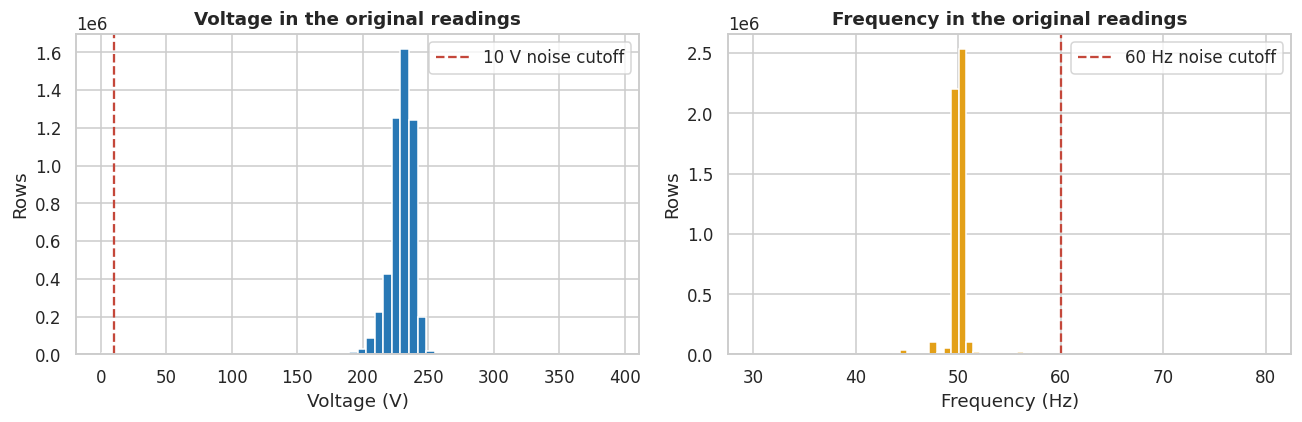

Voltage summary:


,count,mean,std,min,1%,50%,99%,max
voltage,5125181.0,229.438105,12.6571,0.707214,200.141443,230.551627,246.110325,391.796322


Frequency summary:


,count,mean,std,min,1%,50%,99%,max
frequency,5125181.0,50.054098,1.491056,30.038148,47.281324,50.027515,52.465897,100.0


In [ ]:
clean["voltage"] = pd.to_numeric(clean["voltage"], errors="coerce")
clean["frequency"] = pd.to_numeric(clean["frequency"], errors="coerce")
missing_measurement = clean[["voltage", "frequency"]].isna().any(axis=1)
clean = exclude_rows(clean, missing_measurement, "Missing or non-numeric voltage/frequency", "Both measurements are needed for this analysis.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean.voltage.clip(upper=400), bins=60, color="#2878B5")
axes[0].axvline(10, color="#C4473A", linestyle="--", label="10 V noise cutoff")
axes[0].set(title="Voltage in the original readings", xlabel="Voltage (V)", ylabel="Rows")
axes[0].legend()
axes[1].hist(clean.frequency.clip(upper=80), bins=70, color="#E3A018")
axes[1].axvline(60, color="#C4473A", linestyle="--", label="60 Hz noise cutoff")
axes[1].set(title="Frequency in the original readings", xlabel="Frequency (Hz)", ylabel="Rows")
axes[1].legend()
plt.tight_layout()
save_figure(fig, "beginner_voltage_frequency_hist")
plt.show()
print("Voltage summary:")
display(clean.voltage.describe(percentiles=[0.01, 0.5, 0.99]).to_frame().T)
print("Frequency summary:")
display(clean.frequency.describe(percentiles=[0.01, 0.5, 0.99]).to_frame().T)


## Unusual voltage and frequency

Sierra Leone's supply is a 50 Hz system, and a normal reading is near 230 V. Two bands are counted separately.

**Sensor noise, quarantined.** Voltage below 10 V, or frequency above 60 Hz. These values are outside what this supply produces, and an earlier review found that they behave like a failed or disconnected sensor.

**Unusual but possible, kept.** Voltage from 10 V to 150 V or above 270 V, and frequency below 43 Hz or from 57 Hz to 60 Hz. A weak grid, an inverter, or a generator can produce these readings. They stay in the data so the model has seen the kind of input a live sensor can send. Dropping them would leave the model without evidence for that part of the measurement range.

Rerun this cell to refresh the counts. The rows removed here are the same noise rows as in the completed run, so the later results still match.


In [ ]:
n_before = len(clean)
noise_voltage = clean.voltage < 10
noise_frequency = clean.frequency > 60
# Count the operating-band flags before the noise rows are removed.
low_voltage = (clean.voltage < 150) & ~noise_voltage
high_voltage = clean.voltage > 270
low_frequency = (clean.frequency < 43) & ~noise_frequency
high_frequency = clean.frequency.between(57, 60, inclusive="both")
unusual_voltage = low_voltage | high_voltage
unusual_frequency = low_frequency | high_frequency

reading_audit = pd.DataFrame({
    "decision": [
        "Quarantine",
        "Quarantine",
        "Quarantine",
        "Keep",
        "Keep",
        "Keep",
        "Keep",
        "Keep",
        "Keep",
    ],
    "rows": [
        int(noise_voltage.sum()),
        int(noise_frequency.sum()),
        int((noise_voltage | noise_frequency).sum()),
        int(low_voltage.sum()),
        int(high_voltage.sum()),
        int(low_frequency.sum()),
        int(high_frequency.sum()),
        int((unusual_voltage | unusual_frequency).sum()),
        int((unusual_voltage & unusual_frequency).sum()),
    ],
}, index=[
    "Voltage below 10 V",
    "Frequency above 60 Hz",
    "Either noise condition",
    "Voltage from 10 V to 150 V",
    "Voltage above 270 V",
    "Frequency below 43 Hz",
    "Frequency from 57 Hz to 60 Hz",
    "Unusual voltage or frequency, kept",
    "Unusual voltage and frequency, kept",
])
reading_audit["share_of_current_rows"] = reading_audit["rows"] / n_before
display(reading_audit.style.format({"rows": "{:,.0f}", "share_of_current_rows": "{:.2%}"}))

clean = exclude_rows(clean, noise_voltage, "Voltage below 10 V", "Below 10 V is treated as sensor noise rather than a supply reading.")
clean = exclude_rows(clean, clean.frequency > 60, "Frequency above 60 Hz", "Above 60 Hz is outside this 50 Hz system and is treated as a spike.")

# Flags record the unusual readings that remain available to the model.
clean["flag_low_voltage"] = clean.voltage < 150
clean["flag_high_voltage"] = clean.voltage > 270
clean["flag_low_frequency"] = clean.frequency < 43
clean["flag_high_frequency"] = clean.frequency.between(57, 60, inclusive="both")
kept_unusual = clean["flag_low_voltage"] | clean["flag_high_voltage"] | clean["flag_low_frequency"] | clean["flag_high_frequency"]
print(f"Unusual readings kept: {int(kept_unusual.sum()):,} of {len(clean):,} rows still in the working table ({kept_unusual.mean():.2%}).")
display(clean.loc[kept_unusual, "active_power_source"].value_counts().to_frame("unusual rows kept"))


,decision,rows,share_of_current_rows
Voltage below 10 V,Quarantine,"7,246",0.14%
Frequency above 60 Hz,Quarantine,"4,654",0.09%
Either noise condition,Quarantine,"8,325",0.16%
Voltage from 10 V to 150 V,Keep,"1,879",0.04%
Voltage above 270 V,Keep,489,0.01%
Frequency below 43 Hz,Keep,327,0.01%
Frequency from 57 Hz to 60 Hz,Keep,"2,615",0.05%
"Unusual voltage or frequency, kept",Keep,"5,236",0.10%
"Unusual voltage and frequency, kept",Keep,74,0.00%


Voltage below 10 V: 7,246 rows moved to quarantine
Frequency above 60 Hz: 1,079 rows moved to quarantine
Unusual readings kept: 5,167 of 5,116,856 rows still in the working table (0.10%).


,unusual rows kept
active_power_source,
generator,3381
grid,1421
solar,353
unknown,12


## Hold out unknown labels

`unknown` means the labelling rule abstained. Those rows are not a fourth class. They are stored and revisited after the model comparison, when a prediction can be suggested for them.


In [ ]:
unknown_mask = clean.active_power_source.eq("unknown")
unknown_rows = clean.loc[unknown_mask].copy().reset_index(drop=True)
print(f"Rows held aside because the rule said unknown: {len(unknown_rows):,}")
if not unknown_rows.empty:
    display(unknown_rows.available_power_sources.value_counts().to_frame("unknown rows"))
clean = exclude_rows(clean, unknown_mask, "Rule label is unknown", "Unknown is an abstention, not a target class; preserve a separate copy for the hybrid demonstration.")
print(f"Labelled rows remaining: {len(clean):,}")
print("Labels now present:", sorted(clean.active_power_source.dropna().unique().tolist()))


Rows held aside because the rule said unknown: 11,691


,unknown rows
available_power_sources,
Grid w/Solar Backup,11323
Solar w/Grid Backup,368


Rule label is unknown: 11,691 rows moved to quarantine
Labelled rows remaining: 5,105,165
Labels now present: ['generator', 'grid', 'solar']


## Assign sensor IDs and check the row count

Room text is shortened to a room name, and each sensor key receives an ID such as `S001`. The gap to the previous reading is calculated within a sensor, not across the whole file. The audit then confirms that kept rows and quarantined rows still equal the original file.


In [ ]:
def room_name_from_text(value):
    text = str(value)
    return text.rsplit(" - ", 1)[0].strip() if " - " in text else text.strip()

clean["room_name"] = clean.room_text.map(room_name_from_text).str.replace("Denpendency", "Dependency", regex=False)
sensor_lookup = clean[["sensor_key", "site_id", "room_name", "available_power_sources", "respondent_id"]].drop_duplicates("sensor_key").sort_values(["site_id", "room_name", "respondent_id"]).reset_index(drop=True)
sensor_lookup["sensor_id"] = [f"S{i + 1:03d}" for i in range(len(sensor_lookup))]
sensor_id_map = sensor_lookup.set_index("sensor_key").sensor_id
clean["sensor_id"] = clean.sensor_key.map(sensor_id_map)
clean = clean.sort_values(["sensor_id", "time"]).reset_index(drop=True)
clean["gap_prev_min"] = clean.groupby("sensor_id").time.diff().dt.total_seconds() / 60
quarantine = pd.concat(quarantine_parts, ignore_index=True) if quarantine_parts else pd.DataFrame()
print(f"Original rows: {N_RAW:,}")
print(f"Clean labelled rows: {len(clean):,}")
print(f"Quarantined rows: {len(quarantine):,}")
print(f"Reconciles to original: {len(clean) + len(quarantine) == N_RAW}")
if len(clean) + len(quarantine) != N_RAW:
    raise AssertionError("Row counts do not reconcile; inspect the audit steps before continuing.")
display(pd.DataFrame(drop_log))
display(clean.head())


Original rows: 5,125,181
Clean labelled rows: 5,105,165
Quarantined rows: 20,016
Reconciles to original: True


,step,reason,evidence_or_rule,rows_removed
0,1,Missing or unparseable timestamp,A timestamp is needed to order readings and ca...,0
1,2,Repeated reading for the same sensor and times...,Keep the first row for each sensor_key and tim...,0
2,3,Missing or non-numeric voltage/frequency,Both measurements are needed for this analysis.,0
3,4,Voltage below 10 V,Below 10 V is treated as sensor noise rather t...,7246
4,5,Frequency above 60 Hz,Above 60 Hz is outside this 50 Hz system and i...,1079
5,6,Rule label is unknown,"Unknown is an abstention, not a target class; ...",11691


,Unnamed: 0,respondent_id,time,site_id,room,voltage,frequency,available_power_sources,active_power_source,room_text,sensor_key,flag_low_voltage,flag_high_voltage,flag_low_frequency,flag_high_frequency,room_name,sensor_id,gap_prev_min
0,1688535,95E7399D,2023-05-15 17:54:03,bonthe,Male ward - Solar & Generator,233.380481,51.588939,Solar & Generator,generator,Male ward - Solar & Generator,bonthe|Male ward - Solar & Generator|95E7399D,False,False,False,False,Male ward,S001,NaN
1,1792550,95E7399D,2023-05-15 17:56:03,bonthe,Male ward - Solar & Generator,233.380481,51.474752,Solar & Generator,generator,Male ward - Solar & Generator,bonthe|Male ward - Solar & Generator|95E7399D,False,False,False,False,Male ward,S001,2.0
2,3847957,95E7399D,2023-05-15 17:58:03,bonthe,Male ward - Solar & Generator,232.673267,51.517181,Solar & Generator,generator,Male ward - Solar & Generator,bonthe|Male ward - Solar & Generator|95E7399D,False,False,False,False,Male ward,S001,2.0
3,4415981,95E7399D,2023-05-15 18:00:03,bonthe,Male ward - Solar & Generator,233.380481,51.482702,Solar & Generator,generator,Male ward - Solar & Generator,bonthe|Male ward - Solar & Generator|95E7399D,False,False,False,False,Male ward,S001,2.0
4,208886,95E7399D,2023-05-15 18:02:03,bonthe,Male ward - Solar & Generator,232.673267,51.482702,Solar & Generator,generator,Male ward - Solar & Generator,bonthe|Male ward - Solar & Generator|95E7399D,False,False,False,False,Male ward,S001,2.0


## Save the cleaned tables

The cleaned labelled rows, the quarantine file, the drop log, and the sensor lookup are written under `/content/outputs`.


In [ ]:
clean.to_csv(OUT_DIR / "clean_labeled_from_raw.csv.gz", index=False)
pd.DataFrame(drop_log).to_csv(OUT_DIR / "cleaning_drop_log.csv", index=False)
quarantine.to_csv(OUT_DIR / "cleaning_quarantine.csv.gz", index=False)
sensor_lookup.to_csv(OUT_DIR / "sensor_lookup_from_raw.csv", index=False)
print("Saved cleaned data, cleaning log, quarantine, and sensor lookup under /content/outputs/.")


Saved cleaned data, cleaning log, quarantine, and sensor lookup under /content/outputs/.


## Separate mixed configurations

Some installed configurations almost always produce one label, so a model is unnecessary there. A configuration is treated as mixed when its most common label is under 99% of its rows. The classifiers are trained on those mixed configurations only.


In [ ]:
print("Rule-produced labels:")
display(clean.active_power_source.value_counts().to_frame("rows"))
config_counts = pd.crosstab(clean.available_power_sources, clean.active_power_source)
config_share = config_counts.div(config_counts.sum(axis=1), axis=0)
config_summary = pd.DataFrame({
    "rows": config_counts.sum(axis=1),
    "most_common_label": config_share.idxmax(axis=1),
    "most_common_share": config_share.max(axis=1),
})
config_summary["room_type"] = np.where(config_summary.most_common_share >= 0.99, "mostly one label", "mixed labels")
config_display = config_summary.sort_values("rows", ascending=False).copy()
config_display["most_common_share"] = config_display["most_common_share"].map("{:.1%}".format)
display(config_display)
MIXED_CONFIGS = config_summary.index[config_summary.most_common_share < 0.99].tolist()
print("Configurations used for the main classification exercise:", MIXED_CONFIGS)


Rule-produced labels:


,rows
active_power_source,
grid,2399361
solar,2159334
generator,546470


,rows,most_common_label,most_common_share,room_type
available_power_sources,,,,
Solar & Generator,2065039,solar,74.2%,mixed labels
Grid w/Solar & Generator Backup,1785108,grid,87.8%,mixed labels
Grid w/Solar Backup,605069,grid,98.1%,mixed labels
Solar,405880,solar,100.0%,mostly one label
Solar w/Grid Backup,142951,grid,99.9%,mostly one label
Grid w/Generator Backup,95696,grid,99.7%,mostly one label
Generator,5422,generator,100.0%,mostly one label


Configurations used for the main classification exercise: ['Grid w/Solar & Generator Backup', 'Grid w/Solar Backup', 'Solar & Generator']


## Compare frequency and voltage by label

The boxes use a sample of the labelled rows so the figure stays readable. They show whether the three power sources occupy different frequency and voltage ranges.


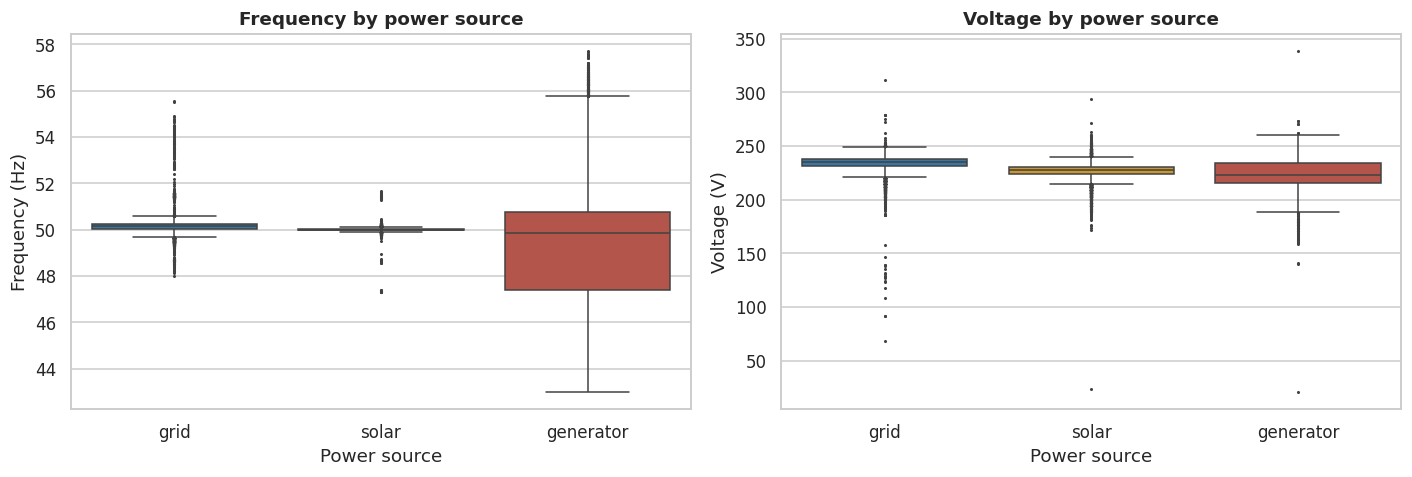

In [ ]:
plot_sample = clean.sample(min(60000, len(clean)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_order = [label for label in CLASSES if label in clean.active_power_source.unique()]
sns.boxplot(data=plot_sample, x="active_power_source", y="frequency", order=plot_order, palette=COLORS, fliersize=1, ax=axes[0])
axes[0].set(title="Frequency by power source", xlabel="Power source", ylabel="Frequency (Hz)")
sns.boxplot(data=plot_sample, x="active_power_source", y="voltage", order=plot_order, palette=COLORS, fliersize=1, ax=axes[1])
axes[1].set(title="Voltage by power source", xlabel="Power source", ylabel="Voltage (V)")
plt.tight_layout()
save_figure(fig, "beginner_frequency_voltage_by_label")
plt.show()


## Inspect the time between readings

Gaps are the minutes from one reading to the next on the same sensor. The histogram clips the display at 120 minutes so the usual gap is visible; the printed shares still use the unclipped values.


,count,mean,std,min,10%,25%,50%,75%,90%,max
minutes between readings,5105130.0,2.84985,68.655252,0.016667,2.0,2.0,2.0,2.0,2.0,56233.45


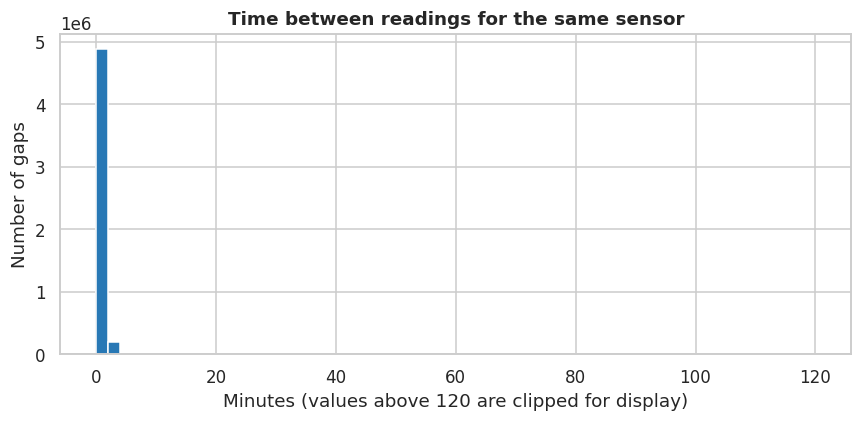

Share of gaps exactly 2 minutes: 90.3%
Share of gaps longer than 60 minutes: 0.1%


In [ ]:
gap_values = clean.gap_prev_min.dropna()
display(gap_values.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame("minutes between readings").T)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(gap_values.clip(upper=120), bins=60, color="#2878B5")
ax.set(title="Time between readings for the same sensor", xlabel="Minutes (values above 120 are clipped for display)", ylabel="Number of gaps")
plt.tight_layout()
save_figure(fig, "beginner_sampling_gaps")
plt.show()
print(f"Share of gaps exactly 2 minutes: {(gap_values == 2).mean():.1%}")
print(f"Share of gaps longer than 60 minutes: {(gap_values > 60).mean():.1%}")


## Build past-only features

Every feature is available at the time of the reading. Nothing is taken from a later row or from another sensor.

`abs_dev_50` is how far frequency sits from the 50 Hz nominal value. The 30-minute mean and standard deviation describe whether frequency is steady or wandering. Most gaps are 2 minutes, so a 10- or 15-minute window is only a handful of readings and mostly reflects one noisy step. Thirty minutes covers the recent half hour, which is long enough to see a drift and still short enough that a change of source is not averaged across the following hour. The window is closed on the right, so it includes the current reading and excludes the future.


In [ ]:
CONFIG_CODE = {name: code for code, name in enumerate(sorted(clean.available_power_sources.unique()))}

def add_past_features(frame):
    data = frame.sort_values(["sensor_id", "time"]).copy().reset_index(drop=True)
    grouped = data.groupby("sensor_id", sort=False)
    data["abs_dev_50"] = (data.frequency - 50).abs()
    data["frequency_change"] = grouped.frequency.diff().fillna(0)
    data["voltage_change"] = grouped.voltage.diff().fillna(0)
    gaps = grouped.time.diff().dt.total_seconds() / 60
    fallback_gap = gaps[gaps > 0].median()
    data["log_gap"] = np.log1p(gaps.fillna(fallback_gap if pd.notna(fallback_gap) else 0).clip(lower=0))
    data["hour_sin"] = np.sin(2 * np.pi * data.time.dt.hour / 24)
    data["hour_cos"] = np.cos(2 * np.pi * data.time.dt.hour / 24)
    data["config_code"] = data.available_power_sources.map(CONFIG_CODE).fillna(-1).astype(float)
    data["frequency_mean_30m"] = 0.0
    data["frequency_std_30m"] = 0.0
    for _, row_indexes in data.groupby("sensor_id", sort=False).groups.items():
        sensor = data.loc[row_indexes].set_index("time")
        # Past and current readings only. Thirty minutes is the recent half hour, not a tuned window.
        rolling = sensor.frequency.rolling("30min", closed="right", min_periods=1)
        data.loc[row_indexes, "frequency_mean_30m"] = rolling.mean().to_numpy()
        data.loc[row_indexes, "frequency_std_30m"] = rolling.std(ddof=0).fillna(0).to_numpy()
    return data

mixed = clean[clean.available_power_sources.isin(MIXED_CONFIGS)].copy()
print(f"Mixed-configuration labelled rows: {len(mixed):,}")
features = add_past_features(mixed)
FEATURES = ["frequency", "voltage", "abs_dev_50", "frequency_change", "voltage_change", "log_gap", "hour_sin", "hour_cos", "frequency_mean_30m", "frequency_std_30m", "config_code"]
features["target"] = features.active_power_source
features = features[features.target.isin(CLASSES)].dropna(subset=FEATURES + ["target"]).reset_index(drop=True)
print(f"Rows ready for modelling: {len(features):,}; number of features: {len(FEATURES)}")
display(features[FEATURES + ["target"]].head())


Mixed-configuration labelled rows: 4,455,216
Rows ready for modelling: 4,455,216; number of features: 11


,frequency,voltage,abs_dev_50,frequency_change,voltage_change,log_gap,hour_sin,hour_cos,frequency_mean_30m,frequency_std_30m,config_code,target
0,51.588939,233.380481,1.588939,0.000000,0.000000,1.098612,-0.965926,-2.588190e-01,51.588939,0.000000,5.0,generator
1,51.474752,233.380481,1.474752,-0.114188,0.000000,1.098612,-0.965926,-2.588190e-01,51.531845,0.057094,5.0,generator
2,51.517181,232.673267,1.517181,0.042429,-0.707214,1.098612,-0.965926,-2.588190e-01,51.526957,0.047127,5.0,generator
3,51.482702,233.380481,1.482702,-0.034479,0.707214,1.098612,-1.000000,-1.836970e-16,51.515893,0.045088,5.0,generator
4,51.482702,232.673267,1.482702,0.000000,-0.707214,1.098612,-1.000000,-1.836970e-16,51.509255,0.042457,5.0,generator


## Three ways to hold out test rows

A random split can place two readings from the same switch-over, a few minutes apart, into different sets. The score then looks stronger than a test on a new hospital or a later month. This cell builds the three checks from the model-comparison notebook.

- **Split A — random, stratified.** 75% train and 25% test, with each power source keeping its share. The model comparison, SHAP chart, and confusion matrix use this split.
- **Split B — leave one site out.** Train on every site except one mid-sized site, and test on that site alone. The held-out site has to contain grid, solar, and generator. A site with no grid rows cannot show whether the model recognizes grid at a new hospital.
- **Split C — time-based.** Train on readings before the 75th percentile of the timestamp, and test on readings from that time onward. This asks whether a model trained on earlier months still works later.

`MAX_TRAIN_ROWS` and `MAX_TEST_ROWS` still apply to Split A. Both are `None` here, so Split A uses every modelling row. Split B and Split C use every row on their side of the cut, so the held-out site and the later months are scored in full.


In [ ]:
if features.target.nunique() < 2:
    raise ValueError("The selected mixed configurations need at least two target labels.")

def stratified_cap(frame, target_column, maximum_rows, seed):
    if maximum_rows is None or len(frame) <= maximum_rows:
        return frame.copy()
    parts = []
    for _, group in frame.groupby(target_column):
        take = max(1, round(maximum_rows * len(group) / len(frame)))
        parts.append(group.sample(min(take, len(group)), random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).iloc[:maximum_rows].copy()

def class_shares(frame):
    return frame.target.value_counts(normalize=True).reindex(CLASSES).fillna(0)

# Split A: random, stratified. Later cells use these two frames.
train_all, test_all = train_test_split(features, test_size=0.25, random_state=RANDOM_STATE, stratify=features.target)
train = stratified_cap(train_all, "target", MAX_TRAIN_ROWS, RANDOM_STATE)
test = stratified_cap(test_all, "target", MAX_TEST_ROWS, RANDOM_STATE + 1)
train_A, test_A = train, test

# Split B: hold out a mid-sized site that still contains all three power sources.
site_class_counts = pd.crosstab(features.site_id, features.target).reindex(columns=CLASSES, fill_value=0)
site_class_counts["rows"] = site_class_counts.sum(axis=1)
site_class_counts = site_class_counts.sort_values("rows", ascending=False)
sites_with_all_classes = site_class_counts.index[(site_class_counts[CLASSES] > 0).all(axis=1)]
if len(sites_with_all_classes) == 0:
    raise ValueError("No site contains grid, solar, and generator, so Split B cannot test all three labels.")
ranked = site_class_counts.loc[sites_with_all_classes, "rows"].sort_values(ascending=False)
HOLD_OUT_SITE = ranked.index[len(ranked) // 2]
train_B = features[features.site_id != HOLD_OUT_SITE].copy()
test_B = features[features.site_id == HOLD_OUT_SITE].copy()

# Split C: earlier months for training, later months for testing.
CUTOFF = features["time"].quantile(0.75)
train_C = features[features.time < CUTOFF].copy()
test_C = features[features.time >= CUTOFF].copy()

print("Label counts by site. Split B uses a site with all three labels.")
display(site_class_counts)
print(f"Split A | random stratified | train {len(train_A):,} of {len(train_all):,} | test {len(test_A):,} of {len(test_all):,}")
print(f"Split B | held-out site: {HOLD_OUT_SITE} | train {len(train_B):,} | test {len(test_B):,}")
print(f"Split C | train before {CUTOFF:%Y-%m-%d %H:%M}, test from then on | train {len(train_C):,} | test {len(test_C):,}")

share_table = pd.DataFrame({
    "A train": class_shares(train_A),
    "A test": class_shares(test_A),
    "B train": class_shares(train_B),
    "B test": class_shares(test_B),
    "C train": class_shares(train_C),
    "C test": class_shares(test_C),
})
display(share_table.style.format("{:.1%}"))


Label counts by site. Split B uses a site with all three labels.


target,grid,solar,generator,rows
site_id,,,,
princess_christian,1145103,79172,7077,1231352
ola_during,1016008,142042,775,1158825
masanga,0,671008,192322,863330
kabala,0,410372,101040,511412
bonthe,0,301561,67026,368587
kambia,0,149154,172556,321710


Split A | random stratified | train 1,000,000 of 3,341,412 | test 299,999 of 1,113,804
Split B | held-out site: ola_during | train 3,296,391 | test 1,158,825
Split C | train before 2024-01-14 21:34, test from then on | train 3,341,410 | test 1,113,806


,A train,A test,B train,B test,C train,C test
target,,,,,,
grid,48.5%,48.5%,34.7%,87.7%,51.6%,39.2%
solar,39.4%,39.4%,48.9%,12.3%,32.8%,59.0%
generator,12.1%,12.1%,16.4%,0.1%,15.6%,1.8%


## Compare the classifiers

The baseline always predicts the most common class. Logistic regression, a random forest, and histogram gradient boosting are then fit on the same rows. Macro F1 gives each class equal weight. Generator recall is the share of true generator readings that the model also calls generator.


In [ ]:
def make_models():
    return {
        "Most-common baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=400, class_weight="balanced", random_state=RANDOM_STATE)),
        "Random forest": RandomForestClassifier(n_estimators=100, max_depth=16, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        "Histogram gradient boosting": HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, l2_regularization=1.0, random_state=RANDOM_STATE),
    }

def evaluate_models(train_frame, test_frame, feature_columns):
    records, fitted = [], {}
    X_train, y_train = train_frame[feature_columns].to_numpy(), train_frame.target.to_numpy()
    X_test, y_test = test_frame[feature_columns].to_numpy(), test_frame.target.to_numpy()
    for name, model in make_models().items():
        started = time.time()
        if name == "Histogram gradient boosting":
            model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train))
        else:
            model.fit(X_train, y_train)
        seconds = time.time() - started
        predicted = model.predict(X_test)
        records.append({
            "model": name,
            "accuracy": accuracy_score(y_test, predicted),
            "macro_f1": f1_score(y_test, predicted, average="macro"),
            "generator_recall": recall_score(y_test, predicted, labels=["generator"], average="macro", zero_division=0),
            "fit_seconds": round(seconds, 1),
            "training_rows": len(train_frame),
        })
        fitted[name] = model
    return pd.DataFrame(records).sort_values("macro_f1", ascending=False), fitted

comparison, fitted_models = evaluate_models(train, test, FEATURES)
comparison.to_csv(OUT_DIR / "beginner_model_comparison.csv", index=False)
display(comparison)


,model,accuracy,macro_f1,generator_recall,fit_seconds,training_rows
2,Random forest,0.956297,0.959832,0.985116,58.5,1000000
3,Histogram gradient boosting,0.955190,0.958130,0.987862,14.1,1000000
1,Logistic regression,0.924180,0.931086,0.966387,13.4,1000000
0,Most-common baseline,0.485075,0.217756,0.000000,1.2,1000000


## Same models on the other two splits

The table above is Split A, the random split. This cell fits the same four models on the held-out site and on the later months. Compare macro F1 across the three columns. A lower score on Split B or Split C means the random split was the easier test.

The class mix of each test set is in the split cell. A held-out site may not contain every power source, so read that site's score together with its class counts.


,split,model,accuracy,macro_f1,generator_recall,fit_seconds,training_rows
0,A (random),Random forest,0.956297,0.959832,0.985116,58.5,1000000
1,A (random),Histogram gradient boosting,0.955190,0.958130,0.987862,14.1,1000000
2,A (random),Logistic regression,0.924180,0.931086,0.966387,13.4,1000000
3,A (random),Most-common baseline,0.485075,0.217756,0.000000,1.2,1000000
4,B (leave-one-site-out),Random forest,0.880688,0.420149,0.731613,191.2,3296391
5,B (leave-one-site-out),Histogram gradient boosting,0.874863,0.390051,0.630968,43.8,3296391
6,B (leave-one-site-out),Logistic regression,0.876685,0.344537,0.073548,37.5,3296391
7,B (leave-one-site-out),Most-common baseline,0.122574,0.072794,0.000000,3.8,3296391
8,C (time-based),Random forest,0.943865,0.947133,0.979614,194.4,3341410
9,C (time-based),Histogram gradient boosting,0.943443,0.945322,0.981728,45.2,3341410


split,A (random),B (leave-one-site-out),C (time-based)
model,,,
Histogram gradient boosting,0.958,0.390,0.945
Logistic regression,0.931,0.345,0.915
Most-common baseline,0.218,0.073,0.188
Random forest,0.960,0.420,0.947


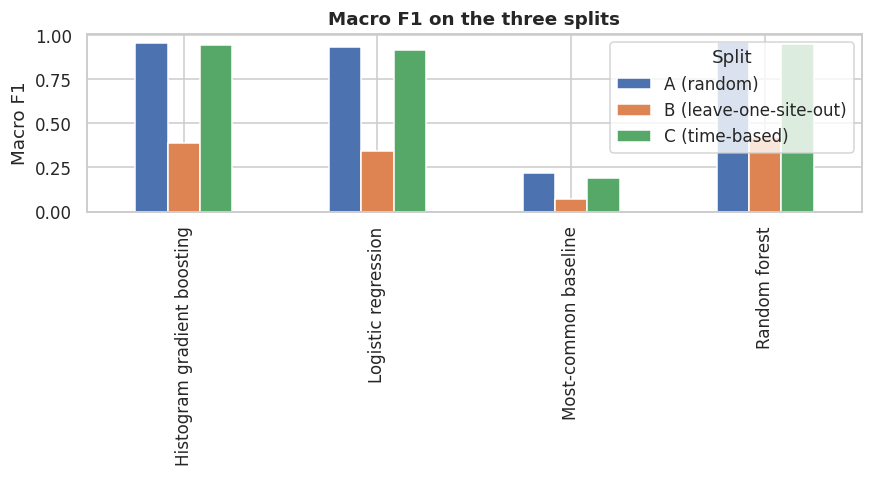

In [ ]:
robust_frames = []
split_a_scores = comparison.copy()
split_a_scores.insert(0, "split", "A (random)")
robust_frames.append(split_a_scores)

for split_name, train_frame, test_frame in [
    ("B (leave-one-site-out)", train_B, test_B),
    ("C (time-based)", train_C, test_C),
]:
    scored, _ = evaluate_models(train_frame, test_frame, FEATURES)
    scored.insert(0, "split", split_name)
    robust_frames.append(scored)

robustness = pd.concat(robust_frames, ignore_index=True)
robustness.to_csv(OUT_DIR / "split_robustness.csv", index=False)
display(robustness)

macro_by_split = robustness.pivot_table(index="model", columns="split", values="macro_f1")
display(macro_by_split.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
macro_by_split.plot.bar(ax=ax)
ax.set(title="Macro F1 on the three splits", ylabel="Macro F1", xlabel="")
ax.legend(title="Split")
plt.tight_layout()
save_figure(fig, "split_robustness_macro_f1")
plt.show()


## Explain the random forest with SHAP

SHAP assigns every feature a push toward or away from a power-source label. In the beeswarm, each dot is one held-out reading: its horizontal position is the SHAP value for that label, and its colour is the feature value. The bar chart ranks features by the average size of that push.

The values use a 1,200-row stratified sample of the test set. TreeSHAP explains the model's raw class margin, so a positive value pushes the prediction toward that label.


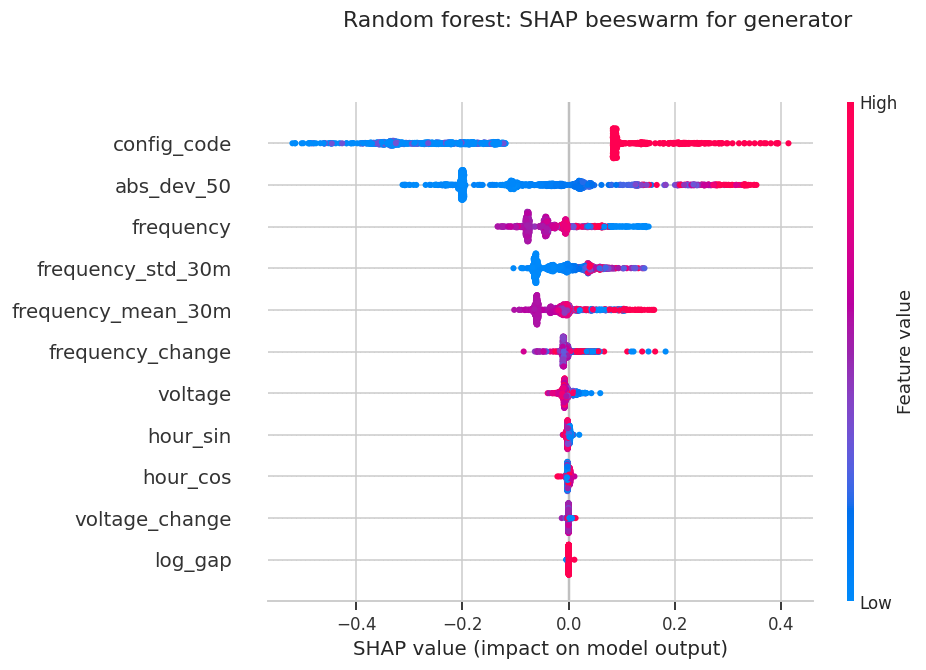

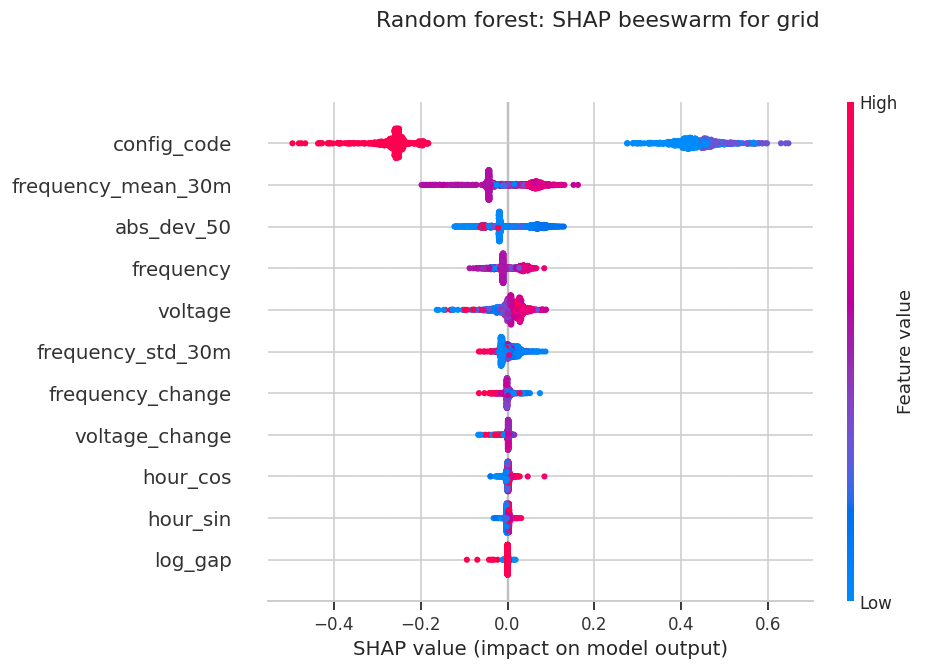

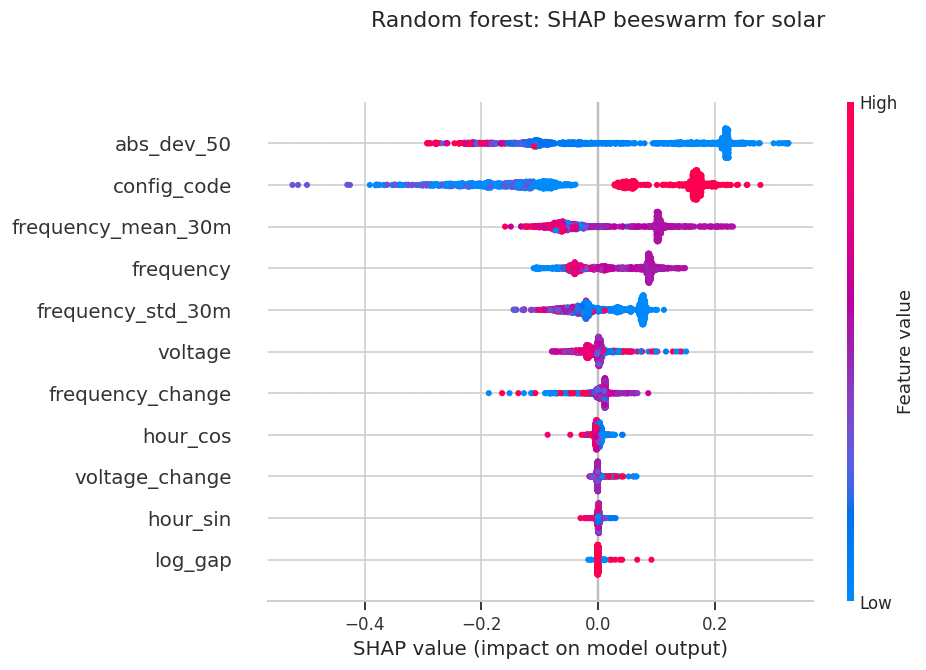

SHAP sample: 1,200 held-out rows


,generator,grid,solar,average
config_code,0.2021,0.3555,0.1534,0.2370
abs_dev_50,0.1321,0.0468,0.1564,0.1118
frequency_mean_30m,0.0380,0.0522,0.0766,0.0556
frequency,0.0520,0.0240,0.0608,0.0456
frequency_std_30m,0.0401,0.0145,0.0470,0.0339
voltage,0.0088,0.0209,0.0142,0.0147
frequency_change,0.0117,0.0053,0.0134,0.0101
hour_cos,0.0020,0.0029,0.0040,0.0030
voltage_change,0.0008,0.0033,0.0027,0.0023
hour_sin,0.0022,0.0028,0.0017,0.0022


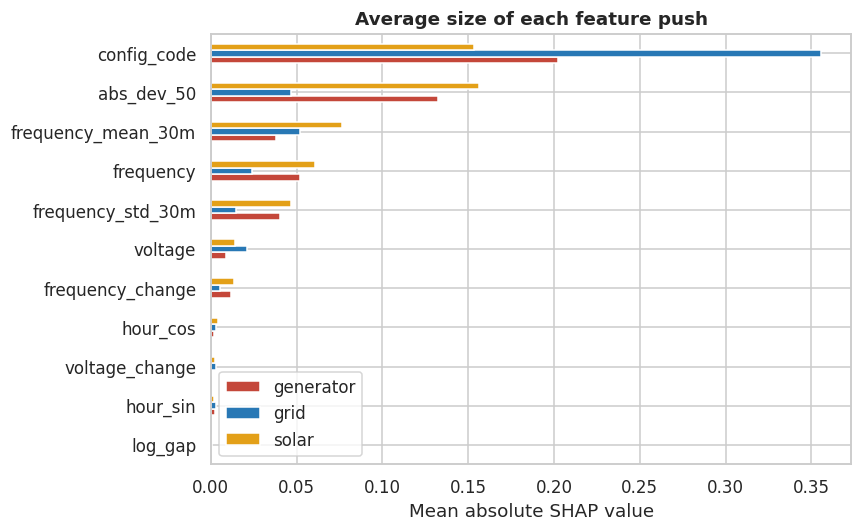

In [ ]:
import shap

rf_model = fitted_models["Random forest"]
SHAP_ROWS = 1200
shap_parts = []
for _, group in test.groupby("target"):
    take = max(1, round(SHAP_ROWS * len(group) / len(test)))
    shap_parts.append(group.sample(n=min(take, len(group)), random_state=RANDOM_STATE))
shap_sample = pd.concat(shap_parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
X_shap = shap_sample[FEATURES]

explainer = shap.TreeExplainer(rf_model)
explanation = explainer(X_shap)
if explanation.values.ndim == 2:
    class_explanations = [explanation]
else:
    class_explanations = [explanation[:, :, class_index] for class_index in range(explanation.values.shape[2])]

mean_abs_columns = []
for class_name, class_explanation in zip(rf_model.classes_, class_explanations):
    mean_abs_columns.append(pd.Series(np.abs(class_explanation.values).mean(axis=0), index=FEATURES, name=class_name))
    shap.plots.beeswarm(class_explanation, max_display=len(FEATURES), show=False)
    fig = plt.gcf()
    fig.suptitle(f"Random forest: SHAP beeswarm for {class_name}", y=1.02)
    save_figure(fig, f"shap_beeswarm_{class_name}")
    plt.show()

shap_importance = pd.concat(mean_abs_columns, axis=1)
shap_importance["average"] = shap_importance.mean(axis=1)
shap_importance = shap_importance.sort_values("average", ascending=False)
print(f"SHAP sample: {len(shap_sample):,} held-out rows")
display(shap_importance.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
bar_values = shap_importance.loc[shap_importance.index[::-1], list(rf_model.classes_)]
bar_values.plot.barh(ax=ax, color=[COLORS[name] for name in rf_model.classes_])
ax.set(title="Average size of each feature push", xlabel="Mean absolute SHAP value")
plt.tight_layout()
save_figure(fig, "shap_mean_abs_bar")
plt.show()


## Inspect the best model's mistakes

The confusion matrix compares the best model's predictions with the rule labels on the test rows. The classification report gives precision, recall, and F1 for each power source.


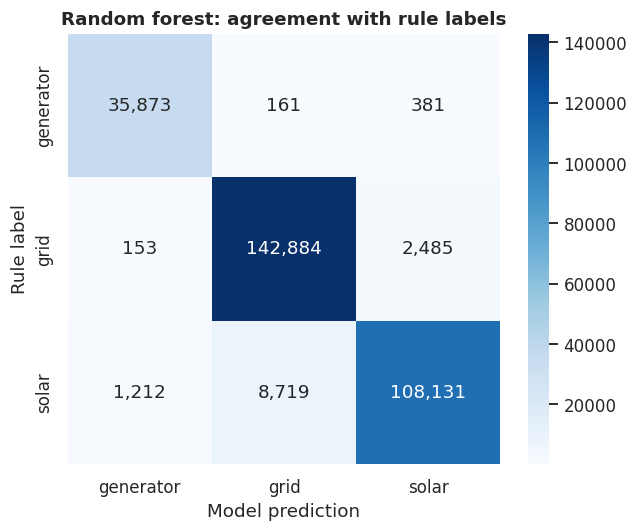

Best comparison model: Random forest
              precision    recall  f1-score   support

   generator       0.96      0.99      0.97     36415
        grid       0.94      0.98      0.96    145522
       solar       0.97      0.92      0.94    118062

    accuracy                           0.96    299999
   macro avg       0.96      0.96      0.96    299999
weighted avg       0.96      0.96      0.96    299999



In [ ]:
best_name = comparison.iloc[0]["model"]
best_model = fitted_models[best_name]
final_model = best_model
test_predictions = best_model.predict(test[FEATURES].to_numpy())
labels_in_data = sorted(test.target.unique())
matrix = confusion_matrix(test.target, test_predictions, labels=labels_in_data)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", xticklabels=labels_in_data, yticklabels=labels_in_data, ax=ax)
ax.set(title=f"{best_name}: agreement with rule labels", xlabel="Model prediction", ylabel="Rule label")
plt.tight_layout()
save_figure(fig, "beginner_confusion_matrix")
plt.show()
print(f"Best comparison model: {best_name}")
print(classification_report(test.target, test_predictions, labels=labels_in_data, zero_division=0))


## Review the disagreements

These are test rows where the model and the rule label differ. The first table shows which pairs of labels disagree most often.


In [ ]:
disagreements = test.copy()
disagreements["model_prediction"] = test_predictions
disagreements = disagreements[disagreements.target != disagreements.model_prediction]
print(f"Disagreements: {len(disagreements):,} of {len(test):,} test rows ({len(disagreements) / max(len(test), 1):.1%})")
display(disagreements.groupby(["target", "model_prediction"]).size().sort_values(ascending=False).to_frame("rows").head(12))
display(disagreements[["sensor_id", "time", "available_power_sources", "target", "model_prediction", "frequency", "voltage"]].head(10))


Disagreements: 13,111 of 299,999 test rows (4.4%)


rows
target    model_prediction      
solar     grid              8719
grid      solar             2485
solar     generator         1212
generator solar              381
          grid               161
grid      generator          153

,sensor_id,time,available_power_sources,target,model_prediction,frequency,voltage
2756427,S023,2023-11-05 21:30:06,Grid w/Solar & Generator Backup,solar,grid,49.990002,207.920792
633478,S006,2023-10-04 20:28:03,Solar & Generator,generator,solar,49.852934,228.429986
2298346,S019,2024-03-18 06:28:03,Grid w/Solar & Generator Backup,solar,grid,50.037528,236.209335
3536294,S031,2023-09-28 21:32:06,Grid w/Solar & Generator Backup,grid,solar,50.000000,228.429986
2475175,S021,2023-07-16 07:32:03,Grid w/Solar & Generator Backup,solar,grid,50.152967,237.623762
4018351,S033,2024-01-24 17:08:06,Grid w/Solar & Generator Backup,solar,grid,50.266412,233.380481
2091002,S019,2023-06-02 02:28:03,Grid w/Solar & Generator Backup,solar,grid,50.062578,231.966054
1501999,S016,2023-08-13 07:22:03,Solar & Generator,solar,generator,50.065085,221.357850
2358317,S020,2023-08-13 11:22:03,Grid w/Solar & Generator Backup,solar,grid,49.912653,217.114569
2735876,S023,2023-10-07 12:10:06,Grid w/Solar & Generator Backup,grid,solar,49.995000,207.920792


## Suggest labels for unknown rows

Unknown rows from a mixed configuration receive a prediction from the best model, retrained on the same modelling rows. Unknown rows from a configuration that is almost always one label receive that configuration's majority label instead. That second assignment is a fallback, not a model prediction.


In [ ]:
if unknown_rows.empty:
    hybrid_predictions = pd.DataFrame()
    print("There are no unknown rows to fill in this input file.")
else:
    context = pd.concat([clean, unknown_rows], ignore_index=True, sort=False)
    context = context.drop_duplicates(["sensor_key", "time"], keep="first").reset_index(drop=True)
    if "sensor_id" not in context.columns:
        context["sensor_id"] = pd.NA
    context["sensor_id"] = context["sensor_id"].fillna(context["sensor_key"].map(sensor_id_map))
    unmapped = context["sensor_id"].isna()
    context.loc[unmapped, "sensor_id"] = "unmapped:" + context.loc[unmapped, "sensor_key"].astype(str)
    context = context.sort_values(["sensor_id", "time"]).reset_index(drop=True)
    context["available_power_sources"] = context.available_power_sources.astype("string")
    context_features = add_past_features(context)
    unknown_features = context_features[context_features.active_power_source.eq("unknown")].copy()
    model_rows = unknown_features[unknown_features.available_power_sources.isin(MIXED_CONFIGS)].copy()
    other_rows = unknown_features[~unknown_features.available_power_sources.isin(MIXED_CONFIGS)].copy()
    final_model = make_models()[best_name]
    final_training = stratified_cap(features, "target", MAX_TRAIN_ROWS, RANDOM_STATE)
    if best_name == "Histogram gradient boosting":
        final_model.fit(
            final_training[FEATURES].to_numpy(),
            final_training.target.to_numpy(),
            sample_weight=compute_sample_weight("balanced", final_training.target.to_numpy()),
        )
    else:
        final_model.fit(final_training[FEATURES].to_numpy(), final_training.target.to_numpy())
    if not model_rows.empty:
        model_rows["final_label"] = final_model.predict(model_rows[FEATURES].to_numpy())
        model_rows["prediction_source"] = "model suggestion for a trained mixed configuration"
    config_majority = config_summary.most_common_label.to_dict()
    if not other_rows.empty:
        other_rows["final_label"] = other_rows.available_power_sources.map(config_majority).fillna("needs review")
        other_rows["prediction_source"] = "configuration-majority fallback; not model prediction"
    hybrid_predictions = pd.concat([model_rows, other_rows], ignore_index=True)
    print(f"Rows receiving a model suggestion: {len(model_rows):,}")
    print(f"Rows receiving a configuration fallback: {len(other_rows):,}")
    if not hybrid_predictions.empty:
        display(hybrid_predictions.groupby(["available_power_sources", "final_label", "prediction_source"]).size().to_frame("rows"))
        hybrid_predictions.to_csv(OUT_DIR / "hybrid_filled_unknown_labels.csv.gz", index=False)


Rows receiving a model suggestion: 11,323
Rows receiving a configuration fallback: 368


rows
available_power_sources final_label prediction_source                                        
Grid w/Solar Backup     generator   model suggestion for a trained mixed configuration      5
                        grid        model suggestion for a trained mixed configuration  11271
                        solar       model suggestion for a trained mixed configuration     47
Solar w/Grid Backup     grid        configuration-majority fallback; not model pred...    368